# NSCLC: Harmony integration, clustering and cell-type annotation

Input: `data/nsclc_combined_preInt.rds` from `preprocess_preInt.ipynb` (QC-filtered, normalized, PCA, `dataset` / `sample` / `compartment` labels, `n_pcs`).

1. UMAP **before** integration
2. **Harmony** with `dataset` as the batch key, and a check that it mixed the datasets but kept the cell types apart
3. **Leiden** clustering and marker genes
4. **SingleR** annotation with the Human Primary Cell Atlas (HPCA)

**Output:** `data/nsclc_integrated_annotated.rds` (input of `pseudobulk_DE.ipynb`). The HPCA reference is downloaded once (internet needed) and cached in `data/references/`. The numbers in *Discussion* boxes are from our run.

## 0. Setup

In [1]:
suppressPackageStartupMessages({
  library(Seurat)
  library(ggplot2)
  library(patchwork)
  library(pheatmap)
})
options(repr.plot.width = 18, repr.plot.height = 5)
stage_times <- c(Setup = Sys.time())

# Paths: Jupyter runs the notebook in scripts/seurat_analysis/, so the project root is two folders up
base_dir <- normalizePath(file.path(getwd(), "..", ".."))
if (!file.exists(file.path(base_dir, "install.sh"))) stop("Open this notebook from scripts/seurat_analysis/ (project root not found)")
input_rds <- file.path(base_dir, "data", "nsclc_combined_preInt.rds")
hpca_file <- file.path(base_dir, "data", "references", "celldex_hpca_2024-02-26.rds")
table_dir <- file.path(base_dir, "data", "tables", "NSCLC_integration")
rds_file  <- file.path(base_dir, "data", "nsclc_integrated_annotated.rds")
dir.create(table_dir, recursive = TRUE, showWarnings = FALSE)
dir.create(dirname(hpca_file), recursive = TRUE, showWarnings = FALSE)

# Parameters
seed               <- 198716
harmony_vars       <- "dataset"   # batch key(s) for Harmony
cluster_resolution <- 0.5         # Leiden resolution: higher = more clusters
set.seed(seed)

## A. Load and look before integration

[1] 15

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”


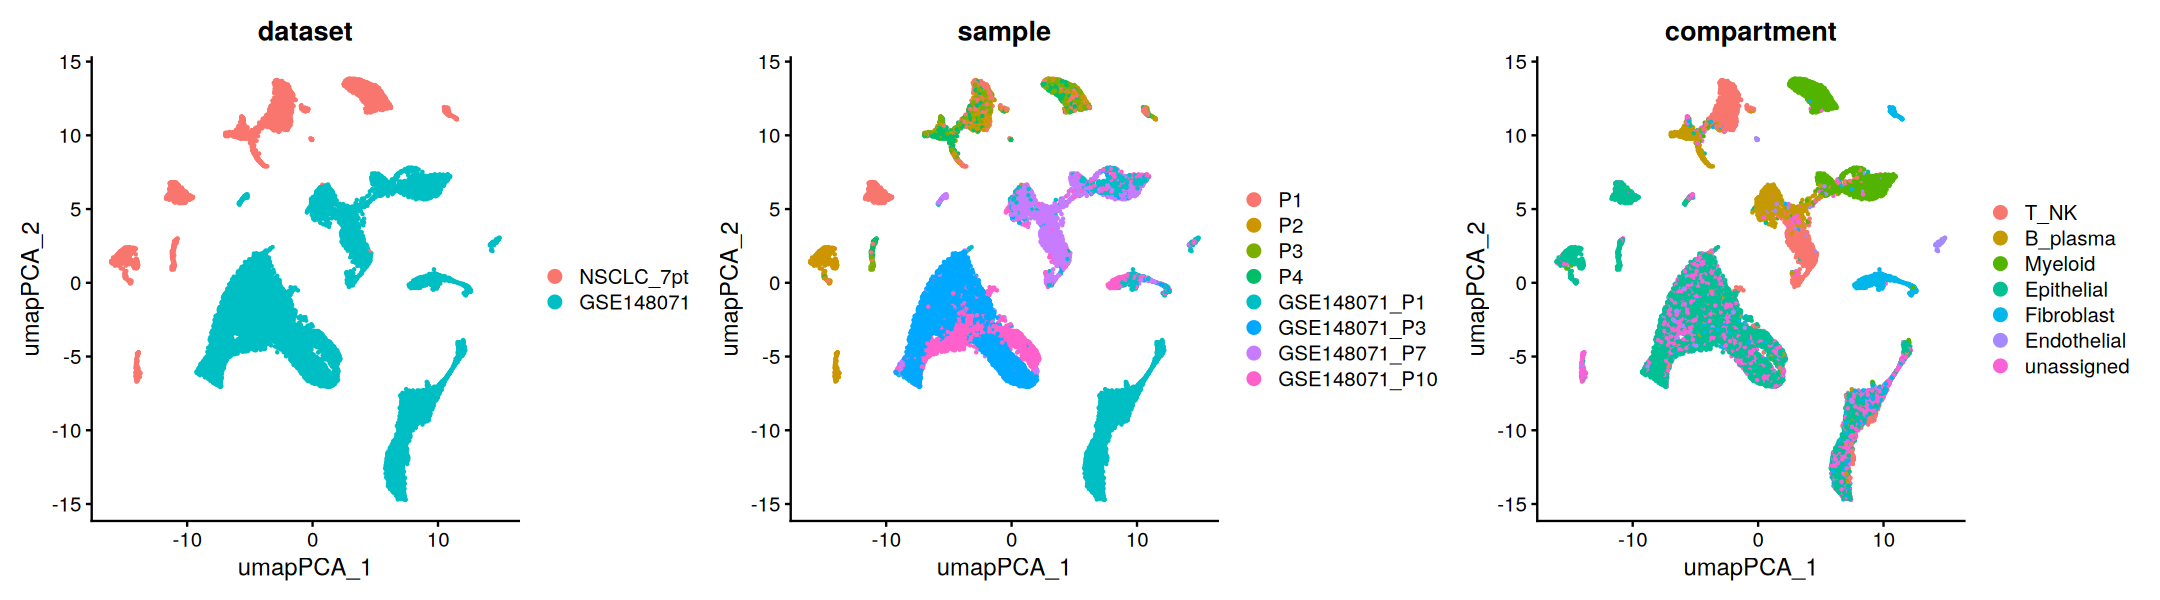

In [2]:
stage_times["A. Load + UMAP before"] <- Sys.time()
nsclc <- readRDS(input_rds)
n_pcs <- nsclc@misc$n_pcs
n_pcs
nsclc <- RunUMAP(nsclc, reduction = "pca", dims = 1:n_pcs, reduction.name = "umap_pca", reduction.key = "umapPCA_",
                 seed.use = seed, verbose = FALSE)
print(DimPlot(nsclc, reduction = "umap_pca", group.by = c("dataset", "sample", "compartment"), shuffle = TRUE, ncol = 3))

> **Discussion.** `preprocess_preInt.ipynb` found a strong dataset effect (same-type cells separated by dataset, silhouette ≈ 0.46). In the UMAP, look for T/NK, myeloid and B cells forming separate NSCLC_7pt and GSE148071 islands, while P1–P4 overlap within NSCLC_7pt.

## B. Harmony integration

Harmony works on the PCA. It repeatedly (1) soft-clusters the cells, favouring clusters that contain every batch, and (2) moves each batch's cells within a cluster by that batch's offset. It returns a corrected embedding (`harmony`); **the counts are not changed**.

**Parameter choice:** `harmony_vars = "dataset"`, the variable with the technical differences. Not `sample`: P1–P4 shared one capture and mixed without correction, and their remaining differences are tumour biology, which integration should not remove.

,before_PCA,after_Harmony
dataset_within_shared,0.46268493,0.04216252
compartment_all_cells,0.05525299,0.08919134


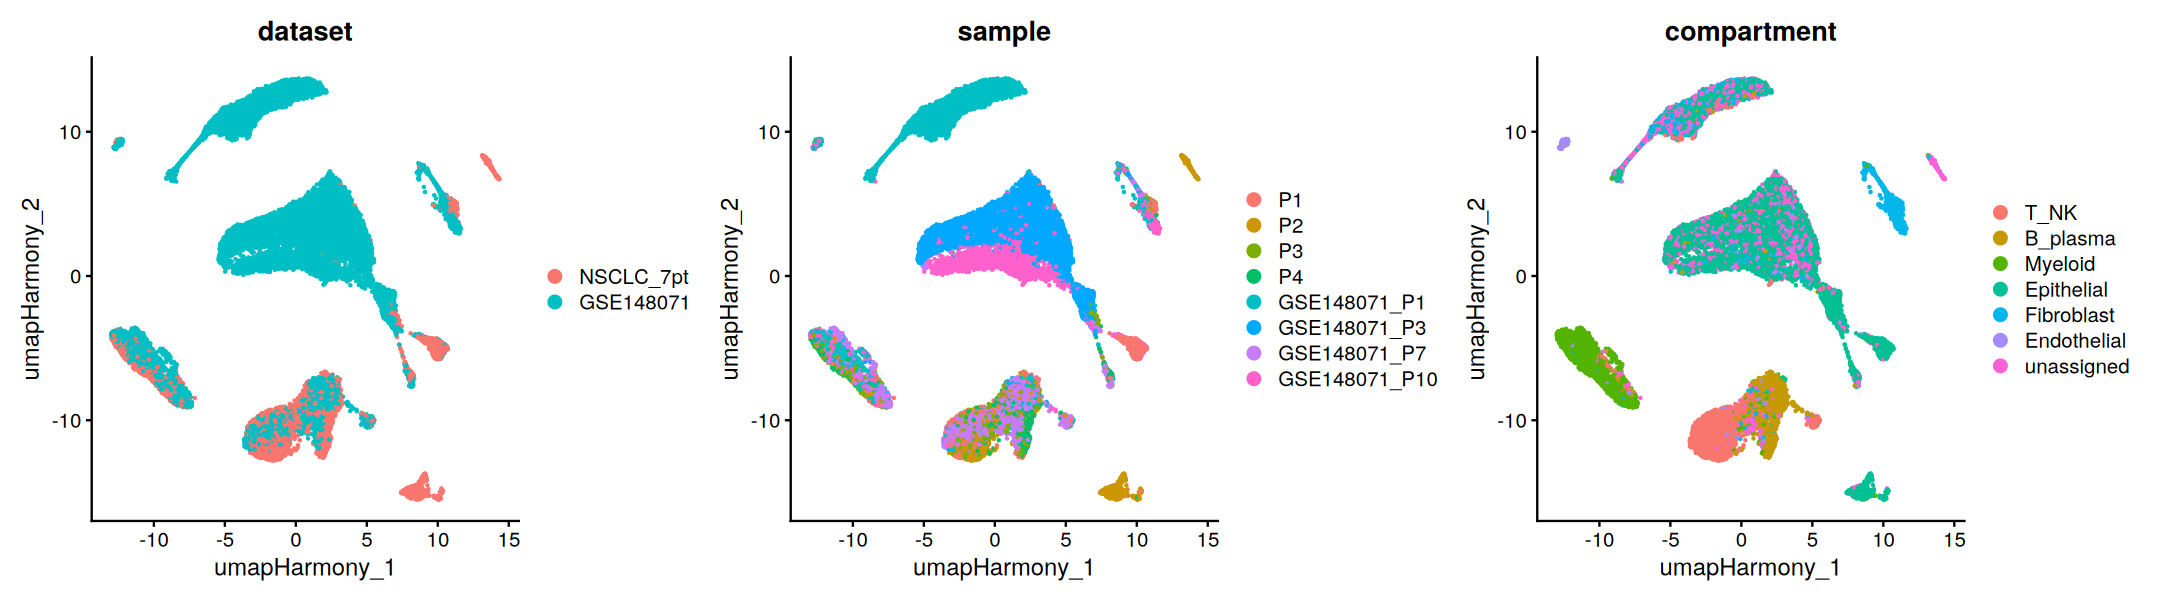

In [3]:
stage_times["B. Harmony"] <- Sys.time()
set.seed(seed)
nsclc <- harmony::RunHarmony(nsclc, group.by.vars = harmony_vars, reduction.use = "pca", dims.use = 1:n_pcs, verbose = FALSE)
nsclc <- RunUMAP(nsclc, reduction = "harmony", dims = 1:n_pcs, reduction.name = "umap_harmony", reduction.key = "umapHarmony_",
                 seed.use = seed, verbose = FALSE)
print(DimPlot(nsclc, reduction = "umap_harmony", group.by = c("dataset", "sample", "compartment"), shuffle = TRUE, ncol = 3))

# Check: silhouette within the largest shared immune/stromal compartment (dataset) and over all cells (compartment)
shared  <- c("T_NK", "B_plasma", "Myeloid", "Fibroblast", "Endothelial")
largest <- names(which.max(table(nsclc$compartment[nsclc$compartment %in% shared])))
set.seed(seed)
idx_shared <- sample(which(nsclc$compartment == largest), min(3000, sum(nsclc$compartment == largest)))
idx_all    <- sample(ncol(nsclc), 3000)
sapply(c(before_PCA = "pca", after_Harmony = "harmony"), function(r) {
  emb <- Embeddings(nsclc, r)[, 1:n_pcs]
  c(dataset_within_shared = summary(cluster::silhouette(as.integer(nsclc$dataset[idx_shared]), dist(emb[idx_shared, ])))$avg.width,
    compartment_all_cells = summary(cluster::silhouette(as.integer(factor(nsclc$compartment[idx_all])), dist(emb[idx_all, ])))$avg.width)
})

> **Discussion.** In our run the dataset silhouette within shared cells fell from **0.46 to 0.04** (datasets now mixed), the extra variance explained by dataset once the cell type is known fell from 0.15 to 0.01, and the compartment measures **rose** slightly (biology kept). Epithelial (tumour) cells stay patient-specific: that is biology, not a failed integration. If the compartments had blurred, the correction would be too strong (lower `theta`).

## C. Clustering (Leiden) and marker genes

A shared-nearest-neighbour graph is built on the Harmony embedding and split into communities with **Leiden** (`algorithm = 4`). `cluster_resolution` sets the granularity. Marker genes per cluster: Wilcoxon test, up to 300 cells per cluster for speed.

       sample
cluster  P1  P2  P3  P4 GSE148071_P1 GSE148071_P3 GSE148071_P7 GSE148071_P10
     1    0   0   0   0            0           98            0             2
     2    6   5  12   7           28            3           26            12
     3    1   0   0   0            0            2            0            96
     4   21  17  13   8            1            0           40             1
     5    0   0   0   0          100            0            0             0
     6    0   0   0   0            0           99            0             1
     7    0   0   0   0          100            0            0             0
     8    7   7   5   8           13            1           53             7
     9    5   5   2   2           24            3            5            54
     10   2   0   9  13            2           46           22             6
     11   5   8  15  39            2            1           29             2
     12   1  99   0   1            0            0            0

For a (much!) faster implementation of the Wilcoxon Rank Sum Test,
(default method for FindMarkers) please install the presto package
--------------------------------------------
install.packages('devtools')
devtools::install_github('immunogenomics/presto')
--------------------------------------------
After installation of presto, Seurat will automatically use the more 
efficient implementation (no further action necessary).
This message will be shown once per session



cluster,top_markers
<fct>,<chr>
1,"CD9, RPL35A, SFN, NFE2L2, FXYD3"
2,"TYROBP, FCER1G, CTSS, AIF1, HLA-DRA"
3,"CLTA, SIGMAR1, AKR1C3, IFI27, EXOSC3"
4,"CD2, TRBC2, PTPRC, CD3D, IL32"
5,"SEC61G, IGFL2-AS1, NIPSNAP2, CCT6A, NSD3"
6,"PTMA, TOP2A, NUSAP1, H2AFZ, PTN"
7,"SNRPD1, CCT6A, NTS, GSTM3, SEC61G"
8,"MZB1, IGHG1, IGHG3, IGKC, IGHG4"
9,"COL1A1, CALD1, COL1A2, SPARC, COL3A1"


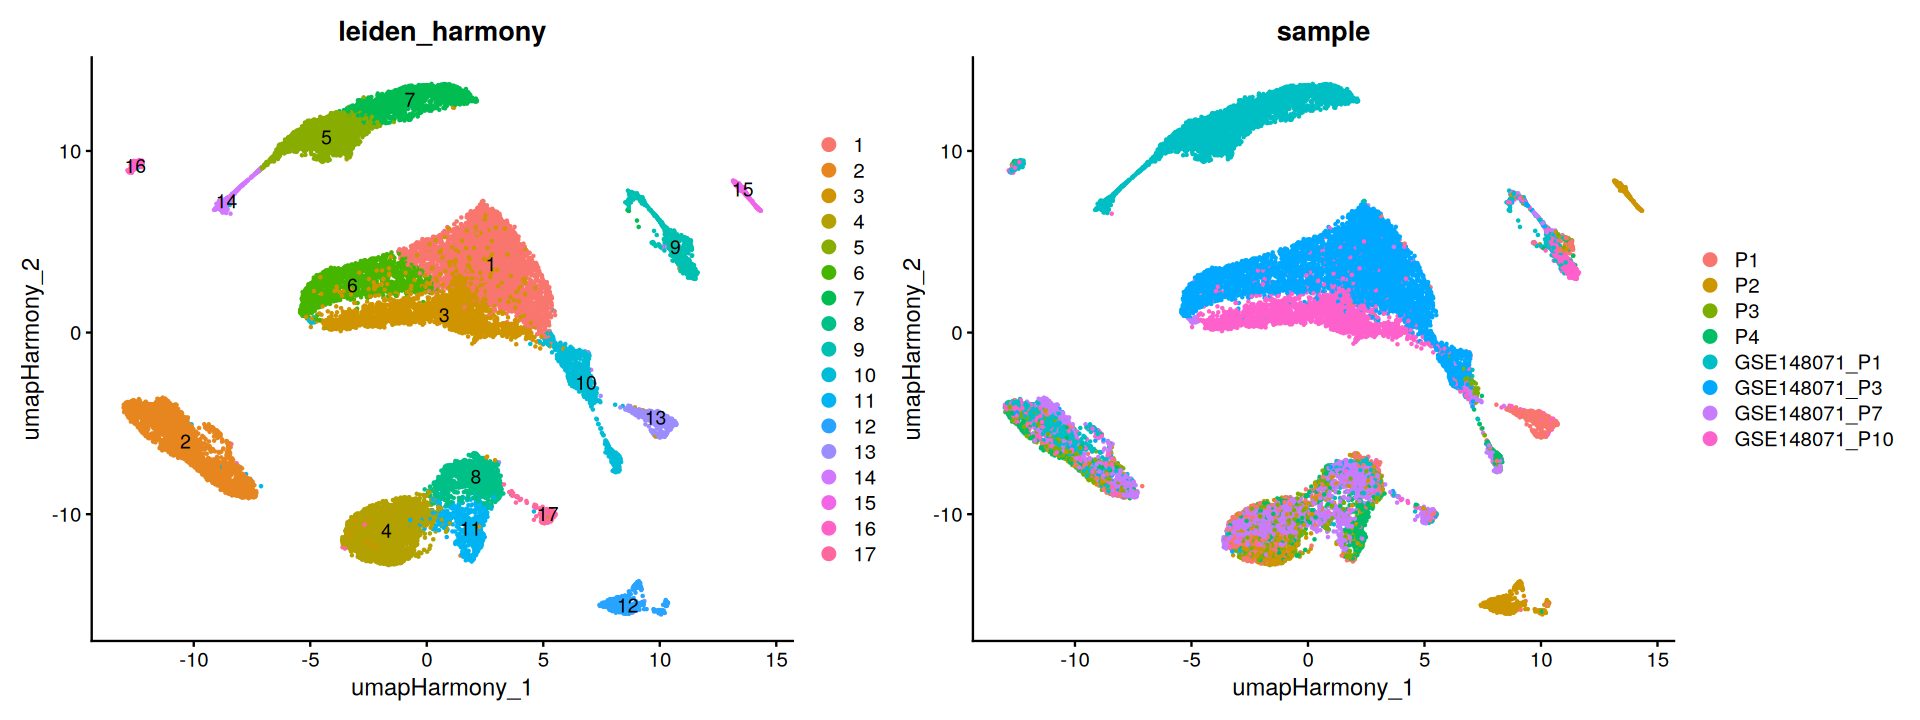

In [4]:
stage_times["C. Clustering + markers"] <- Sys.time()
nsclc <- FindNeighbors(nsclc, reduction = "harmony", dims = 1:n_pcs, verbose = FALSE)
nsclc <- FindClusters(nsclc, resolution = cluster_resolution, algorithm = 4, random.seed = seed,
                      cluster.name = "leiden_harmony", verbose = FALSE)
options(repr.plot.width = 16, repr.plot.height = 6)
print(DimPlot(nsclc, reduction = "umap_harmony", group.by = "leiden_harmony", label = TRUE) |
      DimPlot(nsclc, reduction = "umap_harmony", group.by = "sample", shuffle = TRUE))
round(100 * prop.table(table(cluster = nsclc$leiden_harmony, sample = nsclc$sample), margin = 1))   # % of each cluster per sample

markers <- FindAllMarkers(nsclc, only.pos = TRUE, min.pct = 0.25, logfc.threshold = 0.5,
                          max.cells.per.ident = 300, random.seed = seed, verbose = FALSE)
write.csv(markers, file.path(table_dir, "cluster_markers.csv"), row.names = FALSE)
markers |> dplyr::group_by(cluster) |> dplyr::arrange(p_val_adj, dplyr::desc(avg_log2FC), .by_group = TRUE) |>
  dplyr::slice_head(n = 5) |> dplyr::summarise(top_markers = paste(gene, collapse = ", "))

> **Discussion (our run: 17 clusters).** Immune and stromal clusters mix both datasets: T cells (*CD2*, *TRBC2*, *CD3D*), proliferating T cells (*MKI67*), myeloid cells (*TYROBP*, *FCER1G*, *AIF1*), plasma cells (*MZB1*, *IGHG1*), B cells (*MS4A1*, *CD37*), fibroblasts (*COL1A1*, *SPARC*), endothelial cells (*VWF*, *RAMP2*). The **epithelial clusters** are mostly patient-specific (tumour cells), including proliferating (*TOP2A*, *NUSAP1*) and squamous (*SPRR1B*, *SPRR3*, *KRT16*) ones. Two clusters come **only from P2** (*TUBB2B*, *OTX2*, *ISL1*): P2-specific tumour cells, likely the "unassigned" P2 arm seen earlier in the P1–P4 PCA. How would a higher or lower `cluster_resolution` change this picture?

## D. Cell-type annotation: SingleR + Human Primary Cell Atlas

SingleR correlates each cluster's expression profile with a reference of purified cell types, on the genes that distinguish the reference labels, and returns the best-matching label. Annotating **clusters** (`clusters =`) is fast and robust; per-cell annotation (drop `clusters =`) shows mixtures but takes several minutes.

**Reference:** the **HPCA** (Mabbott *et al.*, 2013; 713 microarray profiles, 37 main labels) comes from the Bioconductor package **`celldex`**; it is not hosted on CELLxGENE. It has **no malignant cells** (tumour cells become `Epithelial_cells`) and few lung-specific types, so labels must be checked against markers.

cluster,cell_type,delta_next
<chr>,<chr>,<dbl>
1,Epithelial_cells,0.066
2,Monocyte,0.056
3,Epithelial_cells,0.083
4,T_cells,0.304
5,Epithelial_cells,0.404
6,Epithelial_cells,0.064
7,Epithelial_cells,0.317
8,B_cell,0.080
9,Fibroblasts,0.047


                   sample
cell_type             P1   P2   P3   P4 GSE148071_P1 GSE148071_P3 GSE148071_P7
  B_cell             131  148  180  409          183           16          898
  Endothelial_cells    2    0    4   12          120            9            6
  Epithelial_cells   522    6   85  120         3672         7175          230
  Fibroblasts         45   54   19   17          235           34           53
  Monocyte           151  131  290  185          698           83          636
  Neurons              3  775    1    4            0            0            0
  T_cells            508  403  316  191           41           12         1045
                   sample
cell_type           GSE148071_P10
  B_cell                       98
  Endothelial_cells            40
  Epithelial_cells           2505
  Fibroblasts                 535
  Monocyte                    305
  Neurons                       0
  T_cells                      49

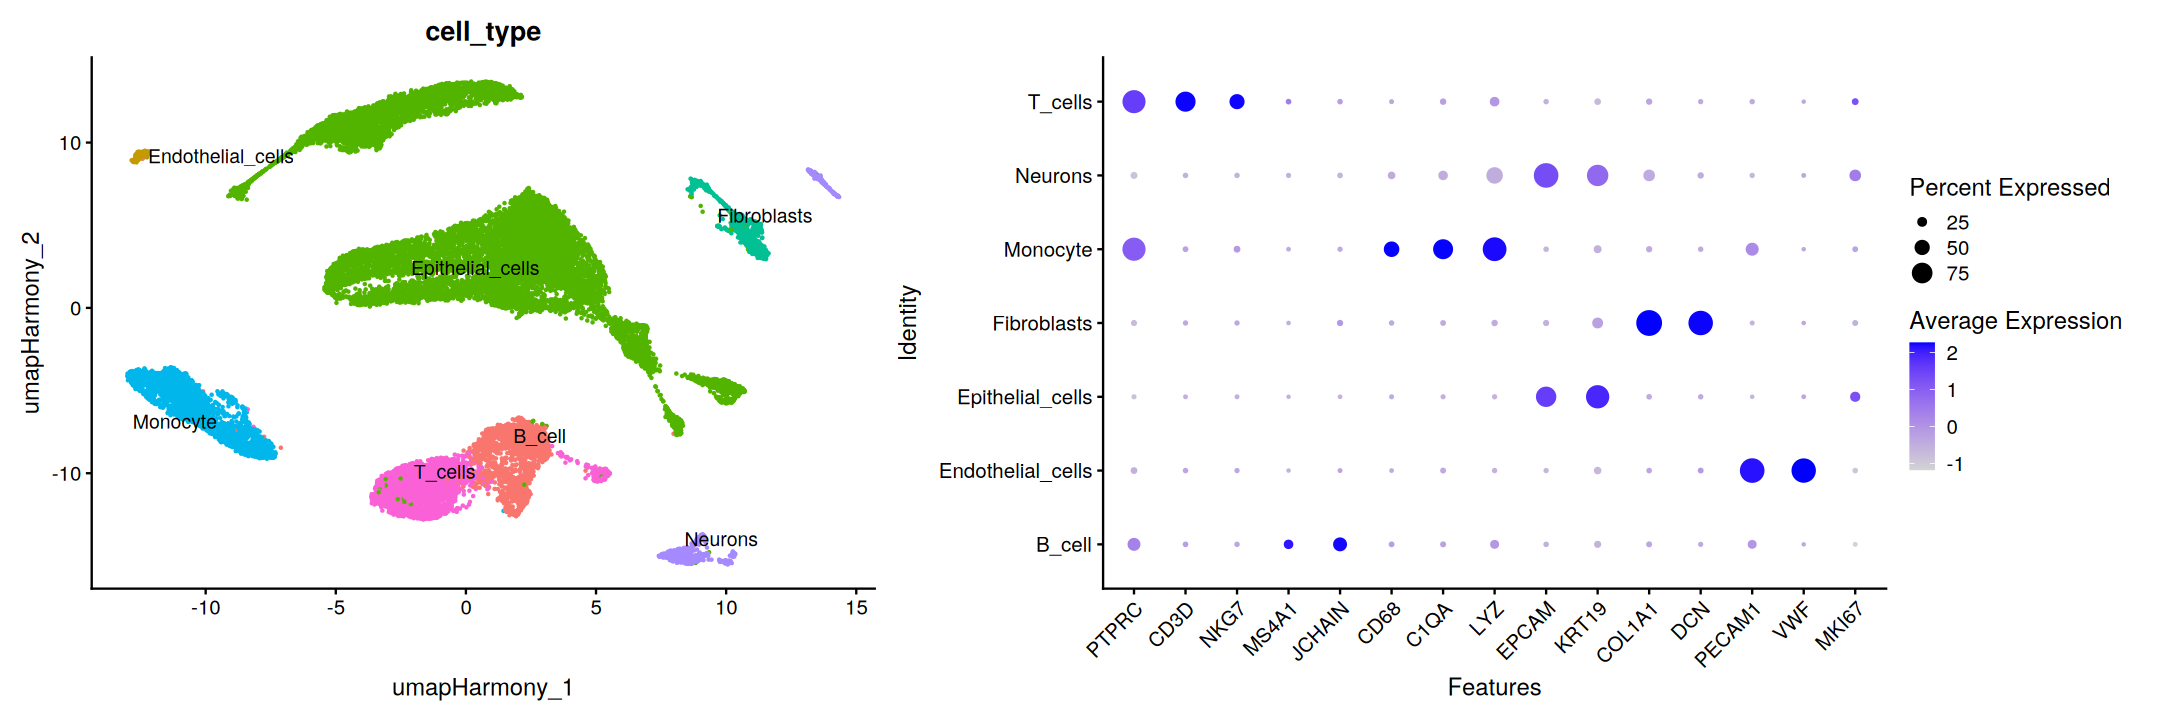

In [5]:
stage_times["D. SingleR"] <- Sys.time()
if (!file.exists(hpca_file)) saveRDS(celldex::fetchReference("hpca", "2024-02-26", realize.assays = TRUE), hpca_file)
hpca <- readRDS(hpca_file)

pred <- SingleR::SingleR(test = LayerData(nsclc, layer = "data"), ref = hpca, labels = hpca$label.main,
                         clusters = nsclc$leiden_harmony)
annotation <- data.frame(cluster = rownames(pred), cell_type = pred$labels, delta_next = round(pred$delta.next, 3))
annotation
nsclc$cell_type <- pred$labels[match(nsclc$leiden_harmony, rownames(pred))]
# Rename after checking the markers, e.g.: nsclc$cell_type[nsclc$leiden_harmony %in% c("12", "15")] <- "Tumour_P2_neural-like"
write.csv(annotation, file.path(table_dir, "cluster_annotation_singler_hpca.csv"), row.names = FALSE)

options(repr.plot.width = 18, repr.plot.height = 6)
canonical <- c("PTPRC", "CD3D", "NKG7", "MS4A1", "JCHAIN", "CD68", "C1QA", "LYZ", "EPCAM", "KRT19",
               "COL1A1", "DCN", "PECAM1", "VWF", "MKI67")
print(DimPlot(nsclc, reduction = "umap_harmony", group.by = "cell_type", label = TRUE, repel = TRUE) + NoLegend() |
      DotPlot(nsclc, features = canonical, group.by = "cell_type") + RotatedAxis())
table(cell_type = nsclc$cell_type, sample = nsclc$sample)

> **Discussion.** In our run the HPCA labels were plausible for the immune and stromal clusters (T_cells, B_cell, Monocyte, Fibroblasts, Endothelial_cells), with known limitations: plasma cells are called `B_cell` (HPCA has no plasma-cell label), and tumour-associated macrophages (*C1QA*, *CD68*) are called `Monocyte`. All tumour clusters became `Epithelial_cells`. The two P2-only clusters were called **`Neurons`**: HPCA has no neuroendocrine or neural-like tumour cells. Check neuroendocrine markers (*ASCL1*, *CHGA*, *SYP*, *INSM1*) before renaming them.
>
> **Composition:** GSE148071 biopsies are mostly epithelial (tumour) cells, NSCLC_7pt samples are immune-rich, and GSE148071 P7 is rich in T and B / plasma cells. These are real differences between the samples, which integration correctly did **not** remove.

   2    3    4    5    6    7 
0.43 0.47 0.38 0.20 0.20 0.12 


sample,cluster,n_cells,B_cell,Endothelial_cells,Epithelial_cells,Fibroblasts,Monocyte,Neurons,T_cells
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
P1,C1,1362,0.0962,0.0015,0.3833,0.0330,0.1109,0.0022,0.3730
P2,C2,1517,0.0976,0.0000,0.0040,0.0356,0.0864,0.5109,0.2657
P3,C1,895,0.2011,0.0045,0.0950,0.0212,0.3240,0.0011,0.3531
P4,C1,938,0.4360,0.0128,0.1279,0.0181,0.1972,0.0043,0.2036
GSE148071_P1,C3,4949,0.0370,0.0242,0.7420,0.0475,0.1410,0.0000,0.0083
GSE148071_P3,C3,7329,0.0022,0.0012,0.9790,0.0046,0.0113,0.0000,0.0016
GSE148071_P7,C1,2868,0.3131,0.0021,0.0802,0.0185,0.2218,0.0000,0.3644
GSE148071_P10,C3,3532,0.0277,0.0113,0.7092,0.1515,0.0864,0.0000,0.0139


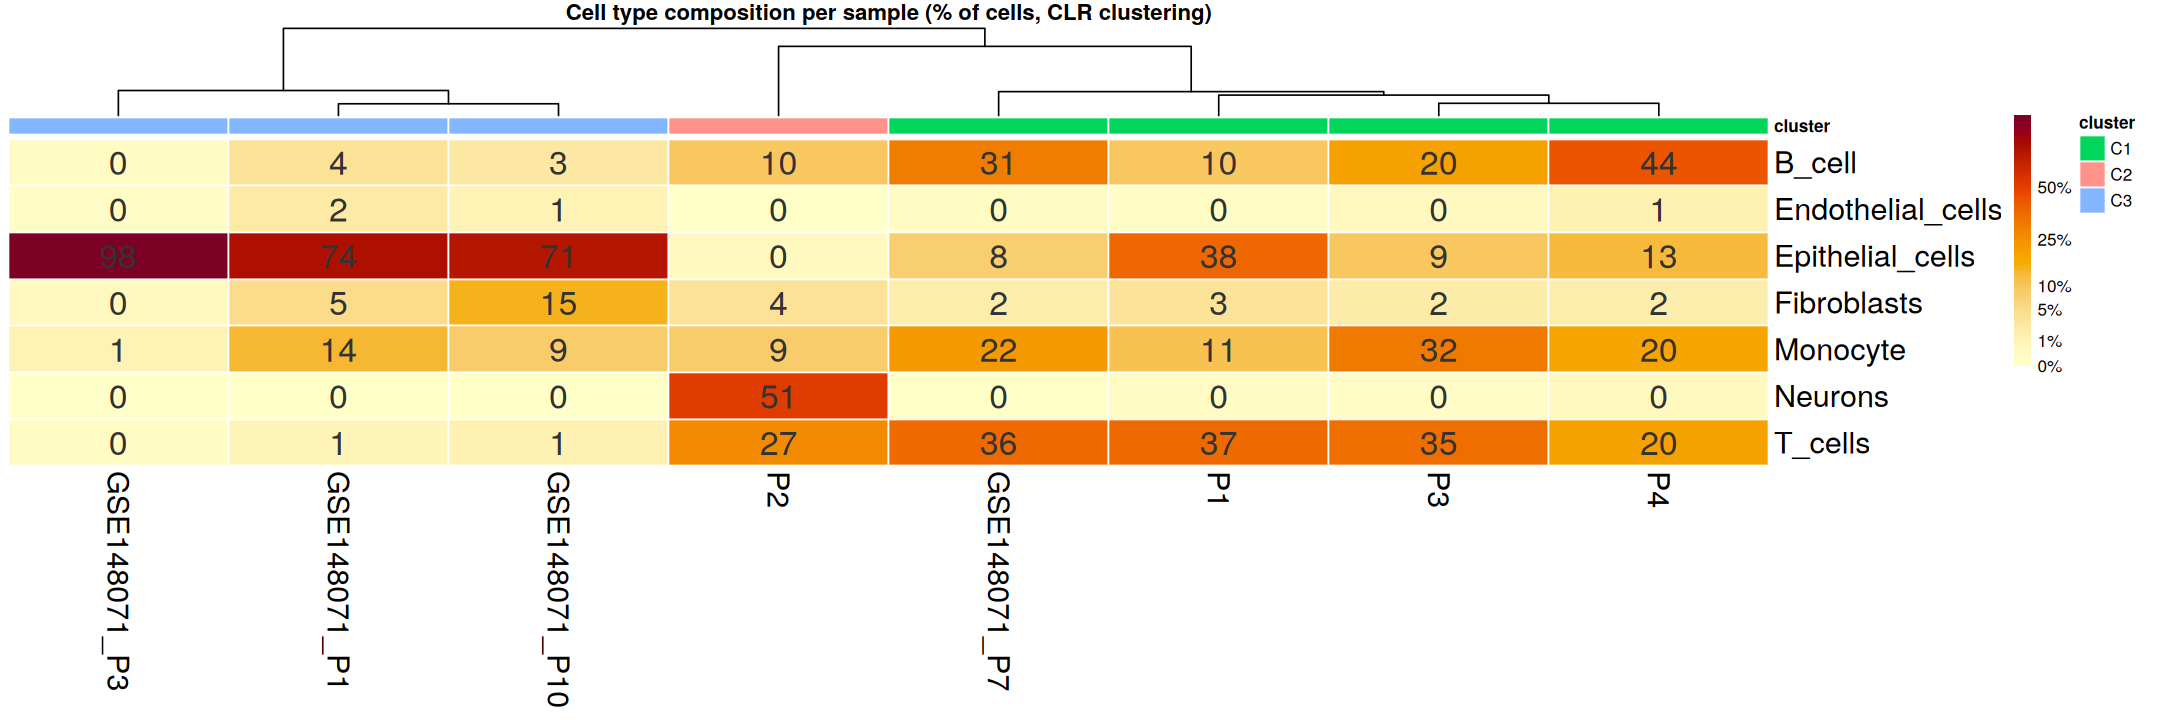

In [6]:
ct <- as.matrix(unclass(table(cell_type = nsclc$cell_type, sample = nsclc$sample)))

# 1. Adjust for total cells per sample
prop    <- prop.table(ct, 2)                         # proportions, columns sum to 1
prop_pc <- prop.table(ct + 0.5, 2)                   # pseudocount so zeros don't give log(0)
logp    <- log(prop_pc)
clr_mat <- sweep(logp, 2, colMeans(logp))            # CLR: log proportion minus per-sample mean

# 2. Cluster samples on CLR values
hc <- hclust(dist(t(clr_mat)), method = "ward.D2")

# 3. Choose k (silhouette; higher is better), then cut the tree
d <- dist(t(clr_mat))
sil <- sapply(2:(ncol(ct) - 1), function(k) mean(cluster::silhouette(cutree(hc, k), d)[, "sil_width"]))
names(sil) <- 2:(ncol(ct) - 1); print(round(sil, 2))
k  <- as.integer(names(which.max(sil)))              # or set manually, e.g. k <- 3
cl <- cutree(hc, k = k)

# 4. Heatmap: colour = proportion (sqrt scale so epithelial doesn't wash out the rest), numbers = % of sample
ann <- data.frame(cluster = factor(paste0("C", cl)), row.names = names(cl))
brk <- c(0, 0.01, 0.05, 0.1, 0.25, 0.5, 1)

pheatmap::pheatmap(sqrt(prop),
                   color = hcl.colors(100, "YlOrRd", rev = TRUE),
                   border_color = "white",
                   cluster_rows = FALSE, cluster_cols = hc,
                   annotation_col = ann,
                   legend_breaks = sqrt(brk), legend_labels = paste0(brk * 100, "%"),
                   display_numbers = round(100 * prop), number_format = "%d", number_color = "grey20",
                   fontsize_row = 18, fontsize_col = 18, fontsize_number = 20,
                   main = "Cell type composition per sample (% of cells, CLR clustering)")

# 5. Save cluster labels with sample totals and proportions
out <- data.frame(sample    = names(cl),
                  cluster   = paste0("C", cl),
                  n_cells   = as.vector(colSums(ct)[names(cl)]),
                  round(t(prop[, names(cl)]), 4),
                  row.names = NULL)
write.csv(out, "sample_composition_clusters.csv", row.names = FALSE)
out

## E. Save

In [7]:
stage_times["E. Save"] <- Sys.time()
saveRDS(nsclc, rds_file)
write.csv(nsclc@meta.data, file.path(table_dir, "cell_metadata_integrated_annotated.csv"))

## Runtime per stage

Seconds from the start of each stage to the start of the next (meaningful for a run from top to bottom without pauses).

In [8]:
stage_times["End"] <- Sys.time()
data.frame(stage = head(names(stage_times), -1), seconds = round(diff(as.numeric(stage_times)), 1))

stage,seconds
<chr>,<dbl>
Setup,0.1
A. Load + UMAP before,65.6
B. Harmony,50.9
C. Clustering + markers,142.8
D. SingleR,19.7
E. Save,114.6


> In our run (with per-cell SingleR, now replaced by the faster cluster-level call) annotation (~4 min) and clustering with marker detection (~2.5 min) were the slowest steps.

In [9]:
sessionInfo()

R version 4.4.3 (2025-02-28)
Platform: x86_64-conda-linux-gnu
Running under: Ubuntu 22.04.5 LTS

Matrix products: default
BLAS/LAPACK: /home/sreeram/miniconda3/envs/seurat_env/lib/libopenblasp-r0.3.34.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

time zone: Asia/Calcutta
tzcode source: system (glibc)

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
[1] future_1.82.0      pheatmap_1.0.13    patchwork_1.3.2    ggplot2_4.0.3     
[5] Seurat_5.5.1       SeuratObject_5.4.0 sp_2.2-3          

loaded via a namespace (and not attached):
  [1] RColorBrewer_1.1-3          jsonlite_2.0.0             
  [3] magrittr_2.0.5              spats